In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve

In [2]:
def true_W(r):
    return (
        -2.0 * np.exp(-r**2) / np.sqrt(np.pi)
        -2.0 * np.exp(-0.5 * r**2) / np.sqrt(2.0 * np.pi)
    )

def true_W_prime(r):
    return (
        4*r*np.exp(-r**2)/np.sqrt(np.pi)
        + 2*r*np.exp(-0.5*r**2)/np.sqrt(2*np.pi)
    )

# Differences
def dx_central(u, dx):
    out = np.zeros_like(u)
    out[1:-1] = (u[2:] - u[:-2]) / (2.0 * dx)
    out[0] = (u[1] - u[0]) / dx
    out[-1] = (u[-1] - u[-2]) / dx
    return out

def dt_central(rho, dt):
    out = np.zeros_like(rho)
    out[1:-1] = (rho[2:] - rho[:-2]) / (2.0 * dt)
    out[0] = (rho[1] - rho[0]) / dt
    out[-1] = (rho[-1] - rho[-2]) / dt
    return out

# RBF kernel
def rbf_kernel(r, s, ell):
    return np.exp(-(r - s) ** 2 / (2.0 * ell**2))

# Recover W by flux inversion
def recover_W_by_flux(rho, x, t, kappa, m, params):
    dx, dt = x[1]-x[0], t[1]-t[0]

    J = params["num_centers"]
    ell, lam = params["ell"], params["lam"]
    rho_cut = params["rho_cut"]
    r_max_fit = params["r_max_fit"]
    r_max_plot = params.get("r_max_plot", r_max_fit)
    num_plot_points = params["num_plot_points"]

    Ltime, N = rho.shape
    Rmat = x[:, None] - x[None, :]
    centers = np.linspace(0.05, r_max_fit, J)

    rho_t = dt_central(rho, dt)

    rows, vals, weights = [], [], []

    for l in range(1, Ltime-1):
        rho_l = rho[l]

        internal = kappa * rho_l**(m-1)
        internal_rhs = dx_central(rho_l * dx_central(internal, dx), dx)

        f = rho_t[l] - internal_rhs

        q_edge = np.zeros(N+1)
        q_edge[1:] = np.cumsum(dx*f)
        q_edge -= np.linspace(0, q_edge[-1], N+1)
        q_center = 0.5*(q_edge[:-1] + q_edge[1:])

        mask = rho_l > rho_cut
        y_l = q_center[mask] / rho_l[mask]

        M_l = np.empty((mask.sum(), J))
        for j, s in enumerate(centers):
            basis = rbf_kernel(Rmat, s, ell) - rbf_kernel(Rmat, -s, ell)
            M_l[:, j] = (dx * (basis @ rho_l))[mask]

        rows.append(M_l)
        vals.append(y_l)
        weights.append(rho_l[mask])

    M = np.vstack(rows)
    y = np.concatenate(vals)
    w = np.concatenate(weights)

    Mw = M * np.sqrt(w)[:, None]
    yw = y * np.sqrt(w)

    A = Mw.T @ Mw + lam*np.eye(J)
    b = Mw.T @ yw

    print("training samples =", M.shape[0])
    print("unknowns =", J)
    print("lambda =", lam)
    print("cond(A) =", np.linalg.cond(A))
    print("r_max_fit =", r_max_fit)
    print("r_max_plot =", r_max_plot)

    beta = cho_solve(
        cho_factor(A + 1e-12*np.eye(J), lower=True),
        b
    )

    r_plot = np.linspace(-r_max_plot, r_max_plot, num_plot_points)

    Wp = sum(
        bj * (rbf_kernel(r_plot, s, ell) - rbf_kernel(r_plot, -s, ell))
        for bj, s in zip(beta, centers)
    )

    W_hat = np.zeros_like(r_plot)
    mid = len(r_plot)//2

    for i in range(mid+1, len(r_plot)):
        dr = r_plot[i] - r_plot[i-1]
        W_hat[i] = W_hat[i-1] + 0.5*(Wp[i] + Wp[i-1])*dr

    for i in range(mid-1, -1, -1):
        dr = r_plot[i+1] - r_plot[i]
        W_hat[i] = W_hat[i+1] - 0.5*(Wp[i] + Wp[i+1])*dr

    W_hat = 0.5*(W_hat + W_hat[::-1])

    return dict(
        r_plot=r_plot,
        W_hat=W_hat,
        Wp_hat=Wp,
        beta=beta,
        centers=centers,
        M_shape=M.shape,
        cond_A=np.linalg.cond(A),
        r_max_fit=r_max_fit,
        r_max_plot=r_max_plot,
    )

def relative_L2_error(f_hat, f_true, mask):
    return (
        np.linalg.norm(f_hat[mask] - f_true[mask])
        /
        np.linalg.norm(f_true[mask])
    )


Dataset = example2_sparse_Cx5_Ct250
rho shape = (61, 192)
dx = 0.0625
dt = 0.025
m = 3
kappa = 0.48
Cx = 5
Ct = 250
Delta_x = 0.0625
Delta_t = 0.025
training samples = 5418
unknowns = 60
lambda = 0.0001
cond(A) = 25951346.644861117
r_max_fit = 4.5
r_max_plot = 6.0
[-2,2] : W = 5.8991e-03, W' = 3.2303e-02
[-4,4] : W = 1.1906e-02, W' = 5.4367e-02
[-6,6] : W = 8.0532e-02, W' = 1.3531e-01


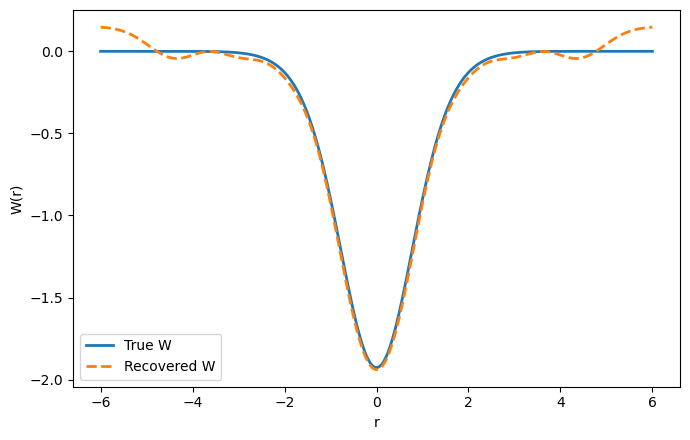

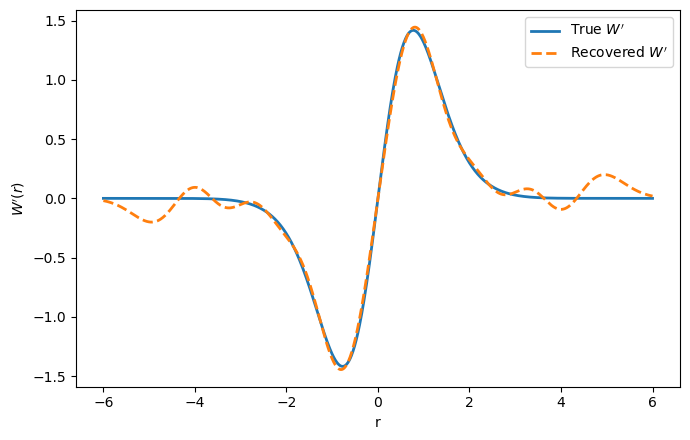

In [3]:
# Example 2: flux inversion with kernel method
# Test 2: sparse data 

# Parameters
params = {
    "data_file": "example2_sparse_Cx5_Ct250.npz",
    "num_centers": 60,
    "ell": 0.60,
    "lam": 1e-4,
    "r_max_fit": 4.5,
    "r_max_plot": 6.0,
    "rho_cut": 1e-4,
    "num_plot_points": 1000,
}

data = np.load(params["data_file"])
tag = os.path.splitext(os.path.basename(params["data_file"]))[0]
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
print("Dataset =", tag)
print("rho shape =", rho.shape)
print("dx =", x[1] - x[0])
print("dt =", t[1] - t[0])
print("m =", m)
print("kappa =", kappa)

if "Cx" in data:
    print("Cx =", int(data["Cx"]))
if "Ct" in data:
    print("Ct =", int(data["Ct"]))
if "Delta_x" in data:
    print("Delta_x =", float(data["Delta_x"]))
if "Delta_t" in data:
    print("Delta_t =", float(data["Delta_t"]))


# Run estimator
result = recover_W_by_flux(rho, x, t, kappa, m, params)
r_plot = result["r_plot"]
W_hat_raw = result["W_hat"]
Wp_hat = result["Wp_hat"]
W_true = true_W(r_plot)
Wp_true = true_W_prime(r_plot)
for R in [2, 4, 6]:
    mask = np.abs(r_plot) <= R
    W_hat_R = W_hat_raw + np.mean(W_true[mask] - W_hat_raw[mask])
    err_W = relative_L2_error(W_hat_R, W_true, mask)
    err_Wp = relative_L2_error(Wp_hat, Wp_true, mask)
    print(f"[-{R},{R}] : W = {err_W:.4e}, W' = {err_Wp:.4e}")

mask_all = np.abs(r_plot) <= params["r_max_plot"]
W_hat = W_hat_raw + np.mean(W_true[mask_all] - W_hat_raw[mask_all])

# save figures
os.makedirs("figures_kernel_flux", exist_ok=True)
plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, W_true, label="True W", linewidth=2)
plt.plot(r_plot, W_hat, "--", label="Recovered W", linewidth=2)
plt.xlabel("r")
plt.ylabel("W(r)")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_W.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_W.pdf", bbox_inches="tight",)
plt.show()


plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, Wp_true, label="True $W'$", linewidth=2)
plt.plot(r_plot, Wp_hat, "--", label="Recovered $W'$", linewidth=2)
plt.xlabel("r")
plt.ylabel(r"$W'(r)$")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_Wprime.png", dpi=300, bbox_inches="tight",)
plt.savefig( f"figures_kernel_flux/{tag}_flux_recovered_Wprime.pdf", bbox_inches="tight",)
plt.show()

Dataset = example2_sparse_Cx2_Ct50
rho shape = (301, 480)
dx = 0.025000000000000355
dt = 0.005
m = 3
kappa = 0.48
Cx = 2
Ct = 50
Delta_x = 0.025
Delta_t = 0.005
training samples = 76761
unknowns = 80
lambda = 0.0001
cond(A) = 253401280.51374182
r_max_fit = 5.0
r_max_plot = 6.0
[-2,2] : W = 9.6763e-04, W' = 5.1690e-03
[-4,4] : W = 1.5363e-03, W' = 1.1181e-02
[-6,6] : W = 8.1688e-03, W' = 2.1146e-02


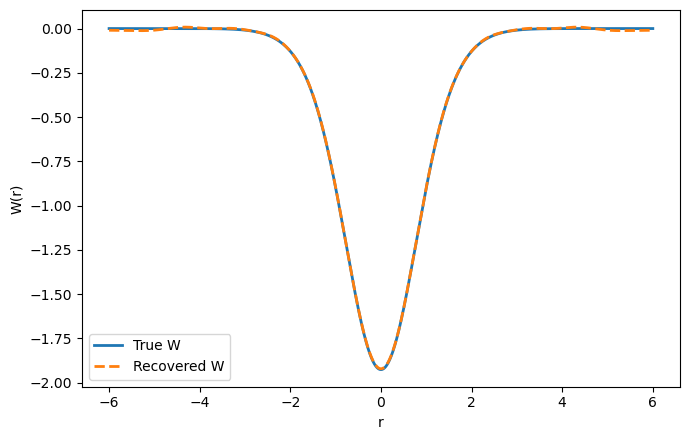

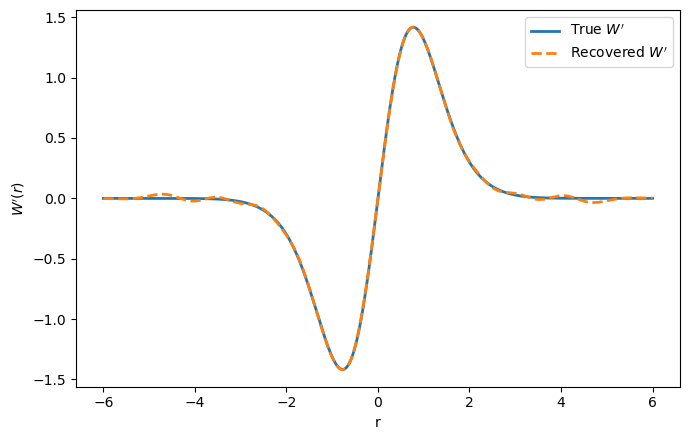

In [4]:
# Example 2: flux inversion with kernel method
# Test 2: fine data 

# Parameters
params = {
    "data_file": "example2_sparse_Cx2_Ct50.npz",
    "num_centers": 80,
    "ell": 0.45,
    "lam": 1e-4,
    "rho_cut": 1e-5,
    "r_max_fit": 5.0,
    "r_max_plot": 6.0,
    "num_plot_points": 2000,
}

data = np.load(params["data_file"])
tag = os.path.splitext(os.path.basename(params["data_file"]))[0]
x = data["x_obs"]
t = data["obs_times"]
rho = data["obs_snapshots"]
m = int(data["m"])
kappa = float(data["kappa"])
print("Dataset =", tag)
print("rho shape =", rho.shape)
print("dx =", x[1] - x[0])
print("dt =", t[1] - t[0])
print("m =", m)
print("kappa =", kappa)

if "Cx" in data:
    print("Cx =", int(data["Cx"]))
if "Ct" in data:
    print("Ct =", int(data["Ct"]))
if "Delta_x" in data:
    print("Delta_x =", float(data["Delta_x"]))
if "Delta_t" in data:
    print("Delta_t =", float(data["Delta_t"]))


# Run estimator
result = recover_W_by_flux(rho, x, t, kappa, m, params)
r_plot = result["r_plot"]
W_hat_raw = result["W_hat"]
Wp_hat = result["Wp_hat"]
W_true = true_W(r_plot)
Wp_true = true_W_prime(r_plot)
for R in [2, 4, 6]:
    mask = np.abs(r_plot) <= R
    W_hat_R = W_hat_raw + np.mean(W_true[mask] - W_hat_raw[mask])
    err_W = relative_L2_error(W_hat_R, W_true, mask)
    err_Wp = relative_L2_error(Wp_hat, Wp_true, mask)
    print(f"[-{R},{R}] : W = {err_W:.4e}, W' = {err_Wp:.4e}")
mask_all = np.abs(r_plot) <= params["r_max_plot"]
W_hat = W_hat_raw + np.mean(W_true[mask_all] - W_hat_raw[mask_all])

# save figures
os.makedirs("figures_kernel_flux", exist_ok=True)
plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, W_true, label="True W", linewidth=2)
plt.plot(r_plot, W_hat, "--", label="Recovered W", linewidth=2)
plt.xlabel("r")
plt.ylabel("W(r)")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_W.png", dpi=300, bbox_inches="tight",)
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_W.pdf", bbox_inches="tight",)
plt.show()


plt.figure(figsize=(7, 4.5))
plt.plot(r_plot, Wp_true, label="True $W'$", linewidth=2)
plt.plot(r_plot, Wp_hat, "--", label="Recovered $W'$", linewidth=2)
plt.xlabel("r")
plt.ylabel(r"$W'(r)$")
plt.legend()
plt.tight_layout()
plt.savefig(f"figures_kernel_flux/{tag}_flux_recovered_Wprime.png", dpi=300, bbox_inches="tight",)
plt.savefig( f"figures_kernel_flux/{tag}_flux_recovered_Wprime.pdf", bbox_inches="tight",)
plt.show()